In [1]:
%load_ext autoreload
%autoreload 2

from nntool.api import NNGraph
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import pickle
import cv2
import torch
import os
import copy
import onnxruntime as ort

import json
from tqdm import tqdm
import glob

import sys
sys.path.append("../../../yolox_people_detection/quantization")
from dataset_generators import CostomCOCODaset, get_annotations
sys.path.append("../../../yolox_people_detection")
from decoding_layer.decoding import decode_C_style

# sys.path.append("../../../YOLOX")
# from yolox.data.data_augment import preproc as preprocess
# from yolox.utils import multiclass_nms, demo_postprocess, vis

sys.path.append("../../../nn-shard-lite")
sys.path.append("../../../nn-shard-lite/src")
sys.path.append("../../../nn-shard-lite/src/utils")
from src.utils.metricsevaluator import MetricsEvaluator

In [2]:
sigmoid = lambda x: 1/(1 + np.exp(-x))

In [3]:
def preprocess(input_image, input_width, input_height, swap = (2, 0, 1)):
    """
    Preprocesses the input image before performing inference.

    Returns:
        image_data: Preprocessed image data ready for inference.
    """
    # Read the input image using OpenCV
    img = cv2.imread(input_image)

    # Get the height and width of the input image
    img_height, img_width = img.shape[:2]

    # Convert the image color space from BGR to RGB
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Resize the image to match the input shape
    img = cv2.resize(img, (input_width, input_height))

    # Normalize the image data by dividing it by 255.0
    image_data = np.array(img) / 255.0

    # Transpose the image to have the channel dimension as the first dimension
    image_data = np.transpose(image_data, swap)  # Channel first

    # Expand the dimensions of the image data to match the expected input shape
    image_data = np.expand_dims(image_data, axis=0).astype(np.float32)

    # Return the preprocessed image data
    return image_data, img_height, img_width

def postprocess(output, input_width, input_height, img_width, img_height, confidence_thres=0.01, iou_thres=0.5):
    """
    Performs post-processing on the model's output to extract bounding boxes, scores, and class IDs.

    Args:
        input_image (numpy.ndarray): The input image.
        output (numpy.ndarray): The output of the model.

    Returns:
        numpy.ndarray: The input image with detections drawn on it.
    """

    # Transpose and squeeze the output to match the expected shape
    outputs = np.transpose(np.squeeze(output[0]))

    # Get the number of rows in the outputs array
    rows = outputs.shape[0]

    # Lists to store the bounding boxes, scores, and class IDs of the detections
    boxes = []
    scores = []
    class_ids = []

    # Calculate the scaling factors for the bounding box coordinates
    x_factor = img_width / input_width
    y_factor = img_height / input_height

    # Iterate over each row in the outputs array
    for i in range(rows):
        # Extract the class scores from the current row
        classes_scores = outputs[i][4:]

        # Find the maximum score among the class scores
        max_score = np.amax(classes_scores)

        # If the maximum score is above the confidence threshold
        if max_score >= confidence_thres:
            # Get the class ID with the highest score
            class_id = np.argmax(classes_scores)

            # Extract the bounding box coordinates from the current row
            x, y, w, h = outputs[i][0], outputs[i][1], outputs[i][2], outputs[i][3]

            # Calculate the scaled coordinates of the bounding box
            left = int((x - w / 2) * x_factor)
            top = int((y - h / 2) * y_factor)
            width = int(w * x_factor)
            height = int(h * y_factor)

            # Add the class ID, score, and box coordinates to the respective lists
            class_ids.append(class_id)
            scores.append(max_score)
            boxes.append([left, top, width, height])

    # Apply non-maximum suppression to filter out overlapping bounding boxes
    indices = cv2.dnn.NMSBoxes(boxes, scores, confidence_thres, iou_thres)

    # Iterate over the selected indices after non-maximum suppression
    final_boxes = []
    final_scores = []
    final_class_ids = []
    for i in indices:
        # Get the box, score, and class ID corresponding to the index
        final_boxes.append(boxes[i])
        final_scores.append(scores[i])
        final_class_ids.append(class_ids[i])

    # Return the modified input image
    return final_boxes, final_scores, final_class_ids

In [4]:
class YOLOXCOCODaset(CostomCOCODaset):
    def __init__(
        self, 
        image_folder, 
        annotations, 
        input_size,
        max_size=500, 
        transpose_to_chw=True,
        input_channels=3,
        img_type = "rgb",
        enable_slicing=True
        ):

        self._img = None
        self._ratio = 1
        
        self.img_height = None
        self.img_width = None
        
        super().__init__(
            image_folder, annotations, input_size, max_size, transpose_to_chw,
            input_channels, img_type, enable_slicing
        )

    def __iter__(self):
        self._idx = 0
        return self

    def __next__(self):

        if self._idx >= self.max_idx:
            raise StopIteration()

        filename = self.annotations[self._idx]["file_name"]

        if self.img_type == "bayer":
            filename = filename.replace("jpg", "png")
        img_file = os.path.join(self.data_dir, filename)

        # read image as BGR
        image = cv2.imread(
            img_file,
            cv2.IMREAD_UNCHANGED
        )

        if self.transpose_to_chw:
            swap = (2, 0, 1)
        else:
            swap = (0, 1, 2)

        self._img = image
        
        image_data, img_height, img_width = preprocess(img_file, *self.input_size, swap)
        self.img_height = img_height
        self.img_width = img_width

        self._idx += 1
        return image_data
    
    def __len__(self):
        return self.max_idx

In [5]:
def clip_stats(stats, n_std):
    clipped_stats = copy.deepcopy(stats)
    if n_std:
        for layer, stat in stats.items():
            min_, max_ = stat['range_out'][0]['min'], stat['range_out'][0]['max']
            mean, std = stat['range_out'][0]['mean'], stat['range_out'][0]['std']
            clipped_stats[layer]['range_out'][0]['min'] = max(min_, mean - n_std * std)
            clipped_stats[layer]['range_out'][0]['max'] = min(max_, mean + n_std * std)
    return clipped_stats

In [6]:
G = NNGraph.load_graph("../../../ultralytics/runs/base-pg2/weights/best_upd.onnx", load_quantization=False)
max_activ_size, total_params = G.total_memory_usage
ops = G.total_ops

print(f"{G.name}:")
print(f"\tMax Active Size:\t{max_activ_size} elements")
print(f"\tTotal # Parameters:\t{total_params} elements")
print(f"\tTotal # Operations:\t{ops / 1e6:.2f} MOps")

## fix the order of the last layer to match that in pytorch 
# G[-1].fixed_order = True

G.adjust_order()
# G.add_dimensions()
G.fusions('scaled_match_group')
G.fusions('expression_matcher')

only align_corners is supported as coordinate_transformation_mode not asymmetric
_model_10_Resize - only round_prefer_ceil is supported for nearest mode not floor
only align_corners is supported as coordinate_transformation_mode not asymmetric
_model_13_Resize - only round_prefer_ceil is supported for nearest mode not floor


best_upd:
	Max Active Size:	786432 elements
	Total # Parameters:	730937 elements
	Total # Operations:	262.43 MOps


In [7]:


# calculate statistics
annotations = get_annotations("../../../YOLOX/datasets/pg_coco/annotations/instances_test.json")

quant_dataset = YOLOXCOCODaset(
    image_folder     = "../../../YOLOX/datasets/pg_coco/test2017",
    annotations      = annotations,
    max_size         = 100,
    input_size       = (256, 256),
    transpose_to_chw = True,
    input_channels   = 3,
    img_type         = "rgb",
    enable_slicing   = False
)
stats = G.collect_statistics(quant_dataset)

# with open("yolov8_stats_8_11.pickle", "rb") as f:
#     stats = pickle.load(f)

stats = clip_stats(stats, n_std = 3)

G.quantize(
    stats,
    graph_options={
        'bits': 8,
        # 'quantized_dimension': 'channel',
        # 'use_ne16': True,
        # 'hwc': True,
    },

    node_options= {
        # 'output_1' : 
        #     {
        #         'scheme' : 'float', 
        #         'float_type': 'float32'
        #     },
        'output_2' : 
            {
                'scheme' : 'float', 
                'float_type': 'float32'
            },
    },
)

Loading annotations for class person...
loading annotations into memory...
Done (t=0.06s)
creating index...
index created!


norm exeeds Q in expression scale operation. If fake quantization is being used this can safely be ignored
norm exeeds Q in expression scale operation. If fake quantization is being used this can safely be ignored


In [17]:
evaluator = MetricsEvaluator(
    is_relative_coordinates=False,
    is_xywh_coordinates=True,
)

with open("../../../YOLOX/datasets/pg_coco/annotations/instances_test.json", "rt") as f:
    test_data = json.load(f)

name_mapper = {}
id_mapper = {}
for i in test_data["images"]:
    name_mapper[i["file_name"]] = i["id"]
    id_mapper[i["id"]] = i["file_name"]

for annotation in test_data["annotations"]:
    evaluator.add_gt_box(
        img_path=annotation["image_id"],
        class_name=annotation["category_id"],
        bbox=annotation["bbox"]
    )

img_pths = sorted(glob.glob("../../../YOLOX/datasets/pg_coco/test2017/*.jpg"))

In [18]:
score_thr = 0.01

for img_pth in tqdm(img_pths):
    img_name = os.path.basename(img_pth)
    image_data, img_height, img_width = preprocess(img_pth, 256, 256)
    
    # execution = G.execute(image_data, quantize=False) #, dequantize=True)
    execution = G.execute(image_data, quantize=True, dequantize=True)
    # output = [execution[out_node.step_idx][0] for out_node in G.outputs()[:1]]
    
    output = [np.concatenate((execution[-3][0][:-1], sigmoid(execution[-1][0])))]

    boxes, scores, class_ids = postprocess(output, 256, 256, img_width, img_height, score_thr)
    
    for b, s, c in zip(boxes, scores, class_ids):
        x, y, w, h = b
        evaluator.add_det_box(
            img_path=name_mapper[os.path.basename(img_pth)],
            class_name=c,
            bbox=[x + w // 20, y + h // 20, w // 3, h // 3],
            confidence=s
        )

100%|██████████| 4558/4558 [47:26<00:00,  1.60it/s]


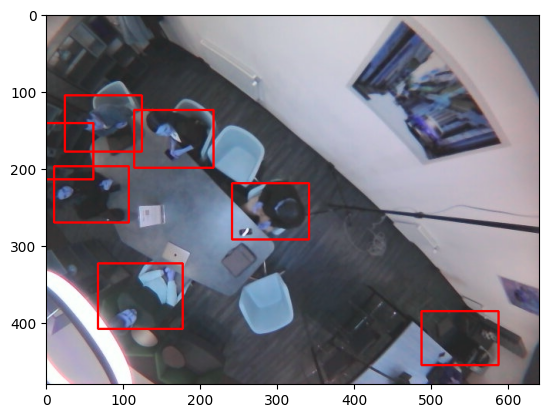

In [19]:
boxes, scores, class_ids = postprocess(output, 256, 256, img_width, img_height, 0.01)
img = cv2.imread(img_pth)

for box in boxes:
    x, y, w, h = box
    # cv2.rectangle(img, (x, y), (x + w, y + h), (255, 0, 0), 2)
    cv2.rectangle(img, (x + w // 20, y + h // 20), (x + w // 20 + w // 3, y + h // 20 + h // 3), (255, 0, 0), 2)

plt.imshow(img)

In [20]:
res = evaluator.eval_conf_vals(0.5, 1)[0]

In [21]:
precision = res["total TP"] / (res["total TP"] + res["total FP"])
recall = res["total TP"] / (res["total positives"])

f_score = 2 * precision * recall / (precision + recall)

precision, recall, f_score

(0.527844671884407, 0.7605725439167209, 0.6231896934695691)

In [22]:
res['AP']

0.6959244983998458

In [23]:
res

{'class': 0,
 'confidence': array([0.8626436 , 0.8626436 , 0.8626436 , ..., 0.01001549, 0.01001549,
        0.01001549]),
 'precision': array([1.        , 1.        , 1.        , ..., 0.52789764, 0.52787116,
        0.52784467]),
 'recall': array([7.22908986e-05, 1.44581797e-04, 2.16872696e-04, ...,
        7.60572544e-01, 7.60572544e-01, 7.60572544e-01]),
 'f1_score': array([1.44571201e-04, 2.89121503e-04, 4.33650911e-04, ...,
        6.23226125e-01, 6.23207667e-01, 6.23189210e-01]),
 'f_beta_score': array([1.44571201e-04, 2.89121503e-04, 4.33650911e-04, ...,
        6.23226125e-01, 6.23207667e-01, 6.23189210e-01]),
 'AP': 0.6959244983998458,
 'interpolated precision': [1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  0.9839181286549707,
  0.9839181286549707,
  0.9839181286549707,
  0.9839181286549707,
  0.9839181286549707,
  0.9839181286549707,
  0.98391812865

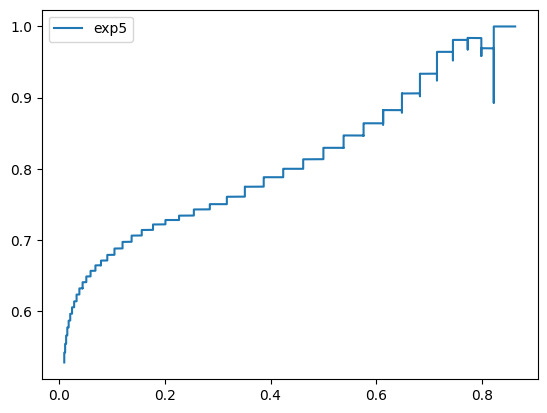

In [24]:
plt.plot(res["confidence"], res["precision"], label="exp5")
plt.legend()

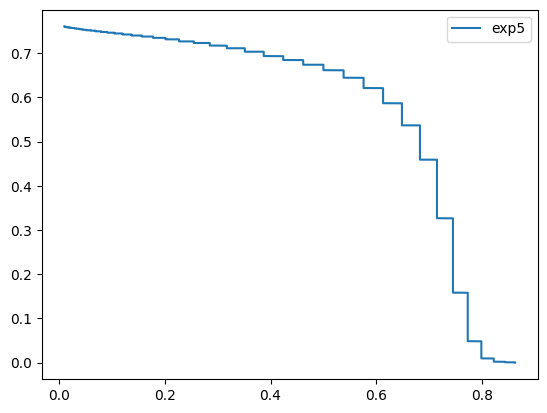

In [25]:
plt.plot(res["confidence"], res["recall"], label="exp5")
plt.legend()

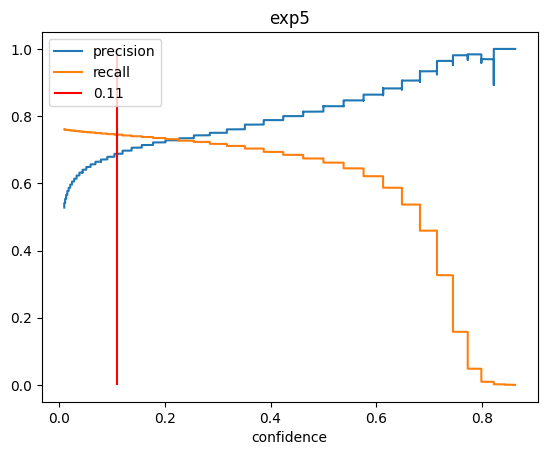

In [26]:
plt.plot(res["confidence"], res["precision"], label="precision")
plt.plot(res["confidence"], res["recall"], label="recall")
plt.title("exp5")
plt.vlines(0.11, 0, 1, label="0.11", colors="r")

plt.xlabel("confidence")
plt.legend()

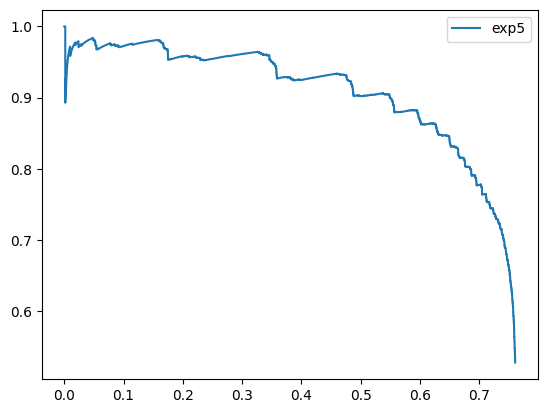

In [27]:
plt.plot(res["recall"], res["precision"], label="exp5")
plt.legend()